# Tahap 1: *Exploratory Data Analysis* (EDA) Data Mentah Uji Klinis RSUA (`HypoSense-001`)

Notebook ini melakukan eksplorasi awal terhadap **data mentah (*raw telemetry*)** hasil perekaman perangkat purwarupa `HypoSense-001` di Rumah Sakit Universitas Airlangga (RSUA) yang diekspor dari tabel `clinical_measurements` Supabase (`clinical_measurements_rsua.csv`).

### Tujuan EDA Awal:
1. Memeriksa struktur rekaman per sesi (`duration_s`, `n_samples`, `n_beats`, `samples`, dan `ibi_raw`).
2. Mengidentifikasi **3 permasalahan utama sinyal mentah** pada perangkat *wearable*:
   - **Duplikasi pengiriman paket *Bluetooth Low Energy* (BLE)** pada detik yang sama.
   - **Fase *warm-up* / belum terkuncinya sensor PPG (`hr == 0` dan `prv == 0`)** saat gelang pertama kali dipasang di pergelangan tangan.
   - **Tumpang-tindih (*overlap*) nilai absolut antar-subjek** serta **interferensi uap air napas (`hum`) pada sensor gas MQ-138 (`voc`)** saat udara napas terperangkap di dalam kabin.

In [1]:
import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BIRU, JINGGA, HIJAU, MERAH, ABU = "#0D9488", "#C9731E", "#1F8A4C", "#B3261E", "#7A8B90"
TINTA, TINTA2, GARIS = "#0F2A30", "#4B5E63", "#D5E3E3"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GARIS, "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "font.size": 9.8,
})

df_raw = pd.read_csv("clinical_measurements_rsua.csv")
HYPO_ID = "93784cfb-22ee-45bb-98e3-e11856760598"  # Subjek 3: Hipoglikemia Terkonfirmasi RSUA

raw_rows = []
audit_sesi = []

for idx, r in df_raw.iterrows():
    sid = f"Subjek {idx+1}"
    is_hypo = 1 if r["id"] == HYPO_ID else 0
    samples_list = json.loads(r["samples"])
    df_s = pd.DataFrame(samples_list)
    n_total_pkt = len(df_s)
    n_unique_detik = df_s["detik"].nunique()
    n_dup_pkt = n_total_pkt - n_unique_detik
    n_zero_hr = int((df_s["hr"] == 0).sum())
    
    audit_sesi.append({
        "Partisipan": sid,
        "ID Rekaman": r["id"][:8],
        "Status Klinis": "HIPOGLIKEMIA" if is_hypo else "Normal",
        "Durasi (dtk)": int(r["duration_s"]),
        "Paket Mentah": n_total_pkt,
        "Detik Unik": n_unique_detik,
        "Duplikat BLE": n_dup_pkt,
        "Titik HR=0 (Belum Kunci)": n_zero_hr,
        "Detak IBI Sah": int(r["n_beats"]),
    })
    
    for s in samples_list:
        raw_rows.append({
            "subj": sid, "is_hypo": is_hypo,
            "detik": s["detik"], "hr": s["hr"], "prv": s["prv"],
            "voc": s["voc"], "temp": s["temp"], "hum": s["hum"]
        })

df_all_raw = pd.DataFrame(raw_rows)
df_audit = pd.DataFrame(audit_sesi)
print("=== AUDIT KUALITAS DATA MENTAH PERANGKAT HYPOSENSE-001 (RSUA) ===")
print(df_audit.to_string(index=False))
print(f"\nTotal paket JSON mentah : {len(df_all_raw)} baris")
print(f"Total paket duplikat BLE: {df_audit['Duplikat BLE'].sum()} baris")
print(f"Total paket HR=0        : {(df_all_raw['hr']==0).sum()} baris")

=== AUDIT KUALITAS DATA MENTAH PERANGKAT HYPOSENSE-001 (RSUA) ===
Partisipan ID Rekaman Status Klinis  Durasi (dtk)  Paket Mentah  Detik Unik  Duplikat BLE  Titik HR=0 (Belum Kunci)  Detak IBI Sah
  Subjek 1   67825ec4        Normal           300            60          60             0                        30             71
  Subjek 2   87d562ea        Normal           300           120          60            60                        76             59
  Subjek 3   93784cfb  HIPOGLIKEMIA           300            60          60             0                        14             62
  Subjek 4   ca369bbf        Normal           300           360          60           300                         6            122
  Subjek 5   d62b4617        Normal           300           175          59           116                       138             37

Total paket JSON mentah : 775 baris
Total paket duplikat BLE: 476 baris
Total paket HR=0        : 264 baris


### Visualisasi Sinyal Mentah & Masalah Tumpang-Tindih Nilai Absolut
Mari kita lihat grafik deret waktu mentah (*raw time-series*) dan distribusi nilai absolut (`hr`, `prv`, `voc`, `temp`, `hum`) sebelum dilakukan *preprocessing*:
- Pada **Subjek 2 dan Subjek 5**, sensor PPG membutuhkan waktu beberapa puluh detik di awal sesi hingga kontak pergelangan tangan stabil (`hr > 0`).
- Pada nilai absolut **HR mentah**, **Subjek 4 (Normal)** memiliki detak jantung dasar yang tinggi ($88\text{–}120\text{ bpm}$), sehingga apabila model langsung menggunakan angka `hr` mentah tanpa normalisasi patokan personal (*personal baseline*), Subjek 4 akan terus-menerus dikira hipoglikemia.

=== STATISTIK DESKRIPTIF SINYAL MENTAH (TERMASUK NOISE & BELUM DINORMALISASI) ===
            hr                    prv  ...  temp    hum                  
          mean    std min  max   mean  ...   max   mean   std   min   max
is_hypo                                ...                               
0        55.28  43.05   0  120  67.64  ...  37.0  60.89  7.08  50.4  79.1
1        72.43  43.88   0  115  72.24  ...  31.9  63.46  0.42  62.9  64.2

[2 rows x 20 columns]


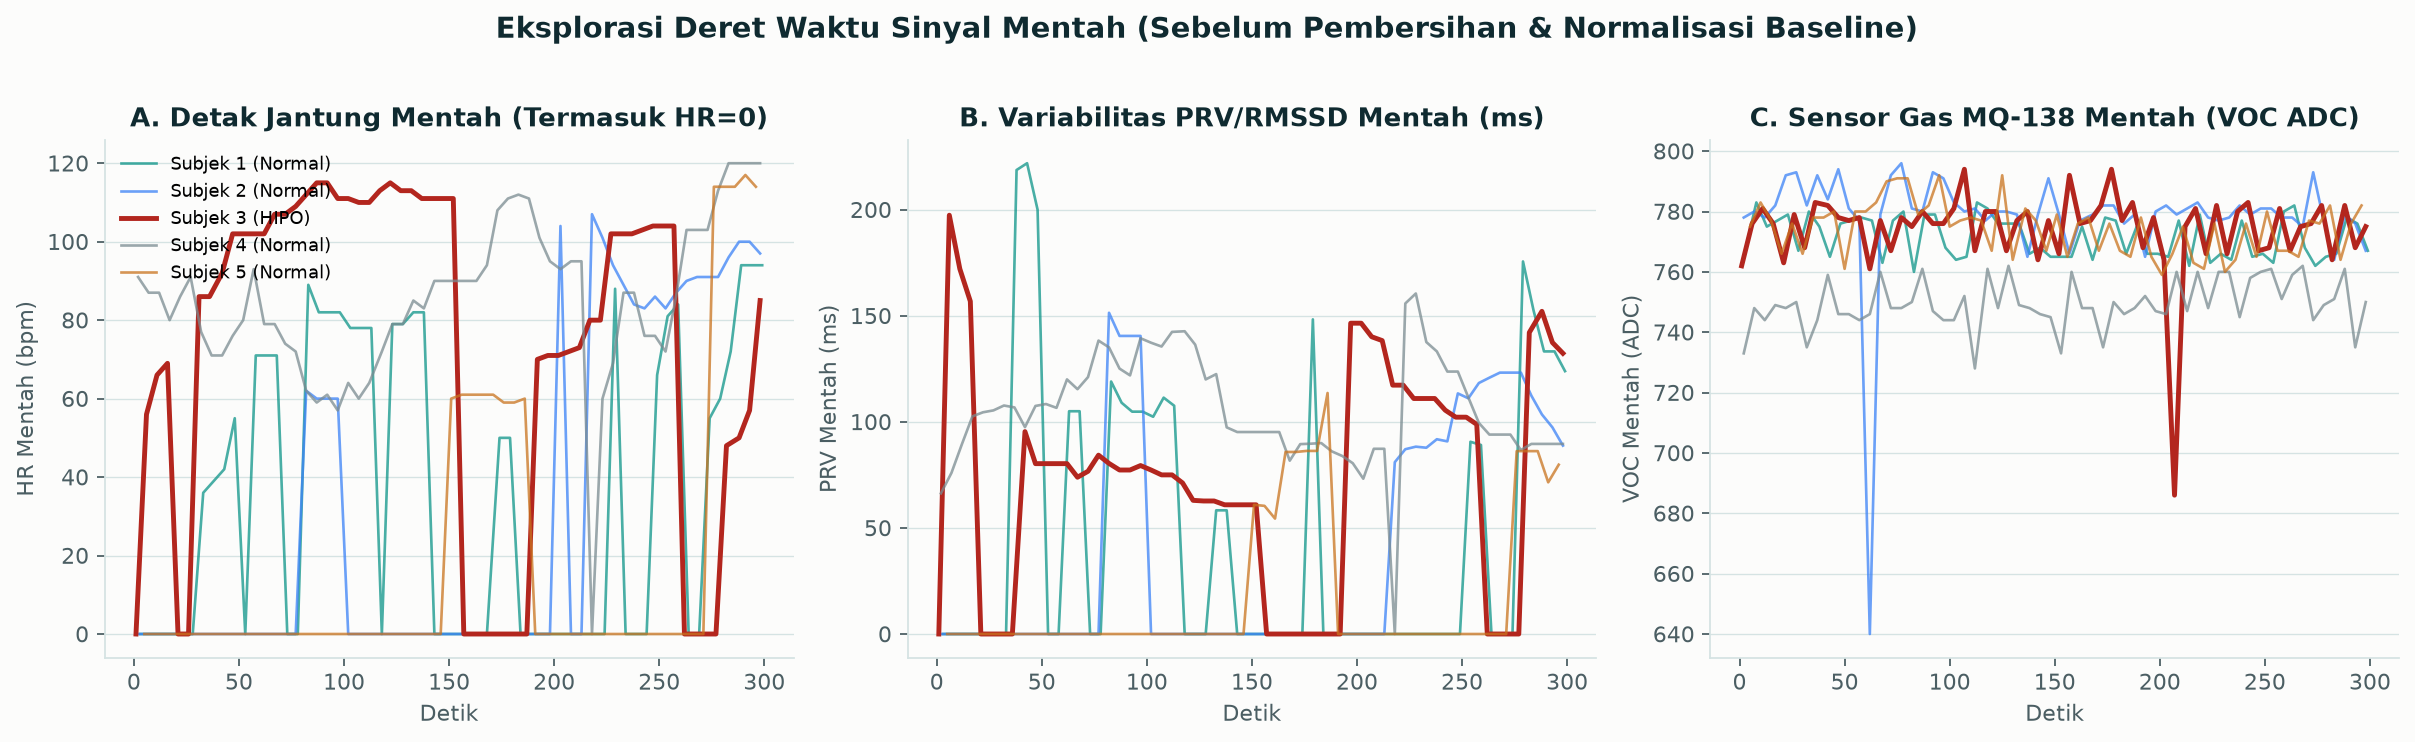

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15.2, 4.5))
palette = {"Subjek 1": BIRU, "Subjek 2": "#3B82F6", "Subjek 3": MERAH, "Subjek 4": ABU, "Subjek 5": JINGGA}

for sid, g in df_all_raw.groupby("subj"):
    lbl = f"{sid} ({'HIPO' if g['is_hypo'].iloc[0] else 'Normal'})"
    lw = 2.2 if g["is_hypo"].iloc[0] else 1.2
    al = 1.0 if g["is_hypo"].iloc[0] else 0.75
    axes[0].plot(g["detik"], g["hr"], color=palette[sid], lw=lw, alpha=al, label=lbl)
    axes[1].plot(g["detik"], g["prv"], color=palette[sid], lw=lw, alpha=al, label=lbl)
    axes[2].plot(g["detik"], g["voc"], color=palette[sid], lw=lw, alpha=al, label=lbl)

axes[0].set_title("A. Detak Jantung Mentah (Termasuk HR=0)", fontweight="bold", color=TINTA)
axes[0].set_xlabel("Detik"); axes[0].set_ylabel("HR Mentah (bpm)")
axes[0].legend(frameon=False, fontsize=8)

axes[1].set_title("B. Variabilitas PRV/RMSSD Mentah (ms)", fontweight="bold", color=TINTA)
axes[1].set_xlabel("Detik"); axes[1].set_ylabel("PRV Mentah (ms)")

axes[2].set_title("C. Sensor Gas MQ-138 Mentah (VOC ADC)", fontweight="bold", color=TINTA)
axes[2].set_xlabel("Detik"); axes[2].set_ylabel("VOC Mentah (ADC)")

for a in axes:
    a.grid(axis="y", color=GARIS, lw=0.6)
    a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)

fig.suptitle("Eksplorasi Deret Waktu Sinyal Mentah (Sebelum Pembersihan & Normalisasi Baseline)", fontweight="bold", fontsize=13, color=TINTA, y=1.02)
plt.tight_layout()
plt.show()

# Statistik Deskriptif Mentah: Normal vs Hipoglikemia
print("=== STATISTIK DESKRIPTIF SINYAL MENTAH (TERMASUK NOISE & BELUM DINORMALISASI) ===")
print(df_all_raw.groupby("is_hypo")[["hr", "prv", "voc", "temp", "hum"]].agg(["mean", "std", "min", "max"]).round(2))